<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


<h1>Fashion-MNIST Project </h1>


**Estimated Time Needed**: 30 min


<h2>Table of Contents</h2>


<p>In this project, you will classify  Fashion-MNIST dataset using convolutional neural networks.</p>
<ul>
  
<ol>
<li><a href="#Prepare-the-Lab-Environment">Prepare the Lab Environment</a>
</li>
<li><a href="#Task-1:-Create-a-Dataset-Class">Task 1: Create a Dataset Class</a>
</li>
 <li><a href="#Task-2:-Build-and-Train-a-Convolutional-Neural-Network"> Task 2: Build and Train a Convolutional Neural Network</a>
<ol>

</ul>


## Prepare the Lab Environment


Download the datasets you needed for this lab.


The following are the PyTorch modules you are going to need:


In [1]:
%%time
%pip install pandas numpy matplotlib
%pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
    --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 80.6 MB/s eta 0:00:00
  Attempting uninstall: torch
    Found existing installation: torch 2.11.0+cpu
    Uninstalling torch-2.11.0+cpu:
      Successfully uninstalled torch-2.11.0+cpu
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.26.0+cpu
    Uninstalling torchvision-0.26.0+cpu:
      Successfully uninstalled torchvision-0.26.0+cpu
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.11.0+cpu
    Uninstalling torchaudio-2.11.0+cpu:
      Successfully uninstalled torchaudio-2.11.0+cpu
CPU times: user 2.98 s, sys: 892 ms, total: 3.87 s
Wall time: 41.9 s


In [ ]:
# !pip install torch
# !pip install torchvision
# !pip install matplotlib

In [2]:
# PyTorch Modules you need for this lab

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dsets
torch.manual_seed(0)

Import the non-PyTorch modules:


In [3]:
# Other non-PyTorch Modules

from matplotlib.pyplot import imshow
import matplotlib.pylab as plt

from PIL import Image

In [4]:
def show_data(data_sample):
    plt.imshow(data_sample[0].numpy().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray')
    plt.title('y = '+ str(data_sample[1]))

<hr>


## Task 1: Create a Dataset Class


In this section, you will load a Dataset object, but first you must transform the dataset. Use the <code>Compose</code> function to perform the following transforms:.
<ol>
    <li>Use the transforms object to<code> Resize </code> to resize the image.</li>
    <li>Use the transforms object to<code> ToTensor </code> to convert the image to a tensor.</li>
</ol>

You will then take a screen shot of your validation data.


Use the Compose function to compose the transforms


In [33]:
# Enter your code here
IMAGE_SIZE = 16
Compose = transforms.Compose([
transforms.Resize((IMAGE_SIZE , IMAGE_SIZE)),
transforms.ToTensor(),

    ])



Create two dataset objects for the Fashion MNIST  dataset. One for training data called <code> dataset_train </code> and one for validation data <code>dataset_val</code>. You will be asked to take a screenshot of several samples.


**Hint:**

<code>dsets.FashionMNIST(root= '.fashion/data', train=???, transform=composed,  download=True)</code>


In [34]:
# Enter your code here
dataset_train = dsets.FashionMNIST(root= '.fashion/data', train=True, transform=Compose,  download=True)
dataset_val = dsets.FashionMNIST(root= '.fashion/data', train=False, transform=Compose,  download=True)

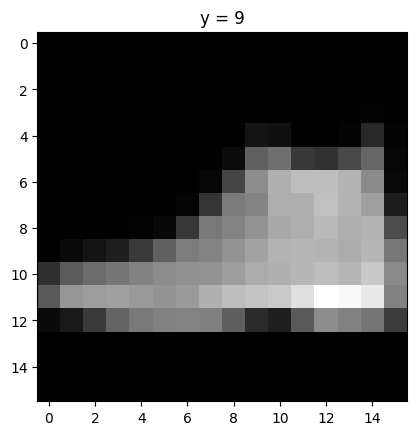

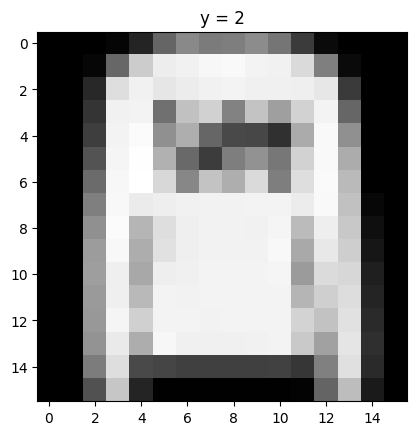

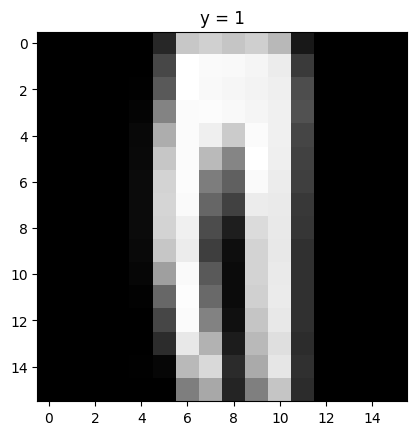

In [35]:


for n,data_sample in enumerate(dataset_val):

    show_data(data_sample)
    plt.show()
    if n==2:
        break


## Task 2: Build and Train a Convolutional Neural Network


Create a Convolutional Neural Network class using ONE of the following constructors. Train the network using the provided code then provide a screenshot of your training cost and accuracy with your validation data.

Constructor using Batch Norm:


In [37]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):
        return self.block(x)


class CNN_batch(nn.Module):

    def __init__(self, number_of_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            ConvBlock(1, 16),
            ConvBlock(16, 32)
        )

        self.classifier = nn.Sequential(
            nn.Linear(32 * 4 * 4, number_of_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x

Constructor for a regular Convolutional Neural Network:


In [18]:
class CNN(nn.Module):

    # Constructor
    def __init__(self, out_1=16, out_2=32,number_of_classes=10):
        super(CNN, self).__init__()
        self.cnn1 = nn.Conv2d(in_channels=1, out_channels=out_1, kernel_size=5, padding=2)
        self.maxpool1=nn.MaxPool2d(kernel_size=2)

        self.cnn2 = nn.Conv2d(in_channels=out_1, out_channels=out_2, kernel_size=5, stride=1, padding=2)
        self.maxpool2=nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 4 * 4, number_of_classes)

    # Prediction
    def forward(self, x):
        x = self.cnn1(x)
        x = torch.relu(x)
        x = self.maxpool1(x)
        x = self.cnn2(x)
        x = torch.relu(x)
        x = self.maxpool2(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        return x

Create the training and validation data loaders:


In [38]:
train_loader = torch.utils.data.DataLoader(dataset=dataset_train, batch_size=100 )
test_loader = torch.utils.data.DataLoader(dataset=dataset_val, batch_size=100 )

Create the convolutional Neural Network object:


In [39]:
model_1 = CNN(out_1=16, out_2=32,number_of_classes=10)
model = CNN_batch()
for param in model.parameters():
  print(param.shape)
print(model.parameters())


torch.Size([16, 1, 5, 5])
torch.Size([16])
torch.Size([16])
torch.Size([16])
torch.Size([32, 16, 5, 5])
torch.Size([32])
torch.Size([32])
torch.Size([32])
torch.Size([10, 512])
torch.Size([10])
<generator object Module.parameters at 0x7fc891681700>


Create the objects for the criterion and the optimizer named <code>criterion</code> and <code>optimizer</code>. Make the optimizer use SGD with a learning rate of 0.1 and the optimizer use Cross Entropy Loss


In [40]:
# Enter your code here
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Here's the code used to train the model:


In [45]:
import time

start_time = time.time()

cost_list = []
accuracy_list = []

N_test = len(dataset_val)
n_epochs = 5

for epoch in range(n_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        optimizer.zero_grad()

        z = model(x)
        loss = criterion(z, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Average training loss
    train_loss = running_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    correct = 0
    val_loss = 0.0

    with torch.no_grad():
        for x_test, y_test in test_loader:

            z = model(x_test)

            # Validation loss
            loss = criterion(z, y_test)
            val_loss += loss.item()

            # Predictions
            _, yhat = torch.max(z, 1)
            correct += (yhat == y_test).sum().item()

    # Average validation loss
    val_loss = val_loss / len(test_loader)

    # Validation accuracy
    accuracy = correct / N_test

    # Store results
    cost_list.append(train_loss)
    accuracy_list.append(accuracy)

    # Print every epoch
    print(
        f"Epoch [{epoch+1}/{n_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {accuracy:.4f}"
    )

print(f"Training time: {time.time() - start_time:.2f} seconds")


Epoch [1/5] Train Loss: 0.1373 | Val Loss: 0.4094 | Val Accuracy: 0.8844
Epoch [2/5] Train Loss: 0.1348 | Val Loss: 0.4047 | Val Accuracy: 0.8858
Epoch [3/5] Train Loss: 0.1324 | Val Loss: 0.4174 | Val Accuracy: 0.8848
Epoch [4/5] Train Loss: 0.1305 | Val Loss: 0.4280 | Val Accuracy: 0.8808
Epoch [5/5] Train Loss: 0.1283 | Val Loss: 0.4280 | Val Accuracy: 0.8834
Training time: 114.37 seconds


You will use the following to plot the Cost and accuracy for each epoch for the training and testing data, respectively.


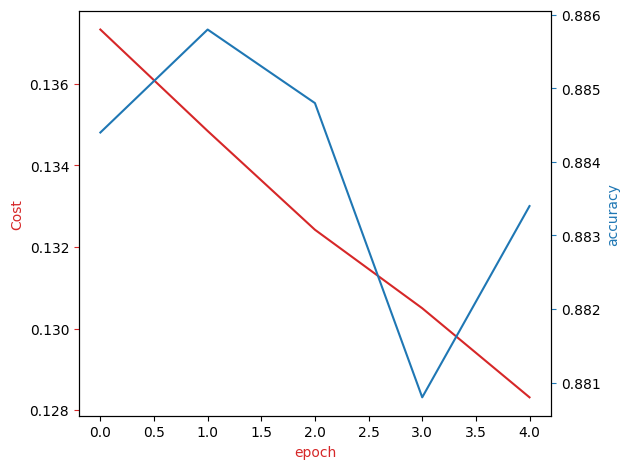

In [46]:
fig, ax1 = plt.subplots()
color = 'tab:red'
ax1.plot(cost_list, color=color)
ax1.set_xlabel('epoch', color=color)
ax1.set_ylabel('Cost', color=color)
ax1.tick_params(axis='y', color=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('accuracy', color=color)
ax2.set_xlabel('epoch', color=color)
ax2.plot( accuracy_list, color=color)
ax2.tick_params(axis='y', color=color)
fig.tight_layout()

dataset: https://github.com/zalandoresearch/fashion-mnist


<h2>About the Authors:</h2>

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<hr>


## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
